# 04 — How does BTC move over seconds and minutes?

**Question:** What do short-horizon returns and volatility mean in our recording?

**By the end:** calculate log returns, understand event time versus clock time,
compare sampling horizons, and read descriptive distributions without declaring
a predictive edge. **Time:** 30–40 minutes. **Inputs:** Binance BTCUSDT trade prints
and operational events; no reference feed is substituted for settlement.

Our sample covers one five-minute interval. That is sufficient for learning the
calculations, not for estimating long-run BTC behavior or choosing a live model.

In [1]:
import sys
from pathlib import Path

# Works when Jupyter starts at the repository root or in the notebook folder.
for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "src/tyrex_pm").exists():
        sys.path.insert(0, str(directory / "src"))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from tyrex_pm.research.tuto_btc5m.analysis import (
    btc_grid,
    finish_plot,
    plot_style,
    trade_frame,
)
from tyrex_pm.research.tuto_btc5m.data import Sample

SAMPLE_PATH = None  # Or Path("/absolute/path/to/your/prepared_sample")
sample = Sample.open(SAMPLE_PATH)
plot_style()
pd.set_option("display.max_columns", 12)
display(pd.Series(sample.describe(), name="Pinned input"))

collection                             2dd3d0d125dc4a9fb5e50daf3f9bfd3e
market                polymarket:condition:0x540c56b66edcf6f1273c7d7...
start_utc                                     2026-10-01 15:45:00+00:00
end_utc                                       2026-10-01 15:50:00+00:00
manifest_sha256       f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a7794458...
integrity_scope       selected_normalized_parts_and_sample_only_not_...
semantic_readiness                                          UNSUPPORTED
Name: Pinned input, dtype: object

## 1. Observe the tape, then choose a clock

The trade tape is irregular: many events can arrive during a busy second. A return
between consecutive trades measures an event-time horizon of varying length.
Here we use local receipt time and backward sample the latest trade on fixed
clock boundaries. Samples older than two seconds are masked. Returns across an
observed transport break or a session/connection change are excluded.

trade_prints           25993
regular_grid_points      300
eligible_points          299
dtype: int64

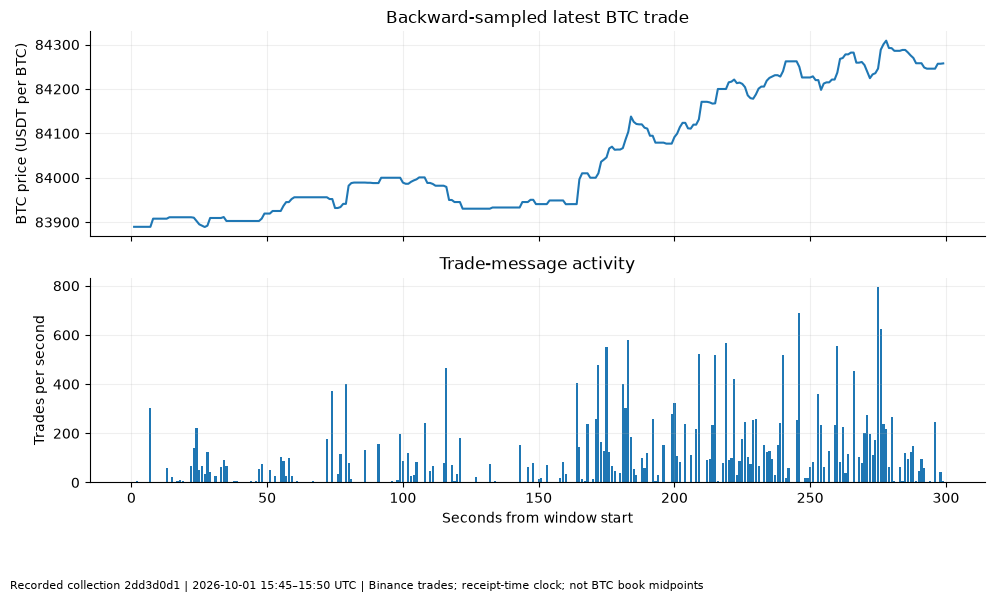

In [2]:
trades = trade_frame(sample)
assert not trades.empty, "This lesson needs recorded Binance trades."
one_second = btc_grid(sample)
display(
    pd.Series(
        {
            "trade_prints": len(trades),
            "regular_grid_points": len(one_second),
            "eligible_points": int(one_second.eligible.sum()),
        }
    )
)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
seconds = (one_second.time - pd.Timestamp(sample.start, tz="UTC")).dt.total_seconds()
axes[0].plot(seconds, one_second.price_float)
axes[0].set(title="Backward-sampled latest BTC trade", ylabel="BTC price (USDT per BTC)")
counts = trades.set_index("time").price_float.resample("1s").count()
axes[1].bar((counts.index - pd.Timestamp(sample.start, tz="UTC")).total_seconds(), counts.values)
axes[1].set(
    title="Trade-message activity", xlabel="Seconds from window start", ylabel="Trades per second"
)
finish_plot(fig, sample, "Binance trades; receipt-time clock; not BTC book midpoints")

## 2. Returns in basis points

For consecutive eligible sampled prices, $r_t = \log(P_t/P_{t-1})$.
Multiplying by 10,000 expresses it in basis points: 1 basis point is 0.01%.
A price level is nonstationary; a return is a change relative to the prior price.

Because these are last trades rather than BTC midpoints, bid/ask bounce can
contribute to short-horizon changes. This extract does not include a Binance book
replay, so it cannot remove that effect by pretending trades are midpoints.

count    298.000000
mean       0.146975
std        1.085559
min       -3.508620
1%        -2.616027
5%        -1.428335
50%        0.000000
95%        1.794543
99%        4.709513
max        6.659636
Name: log_return_bps, dtype: float64

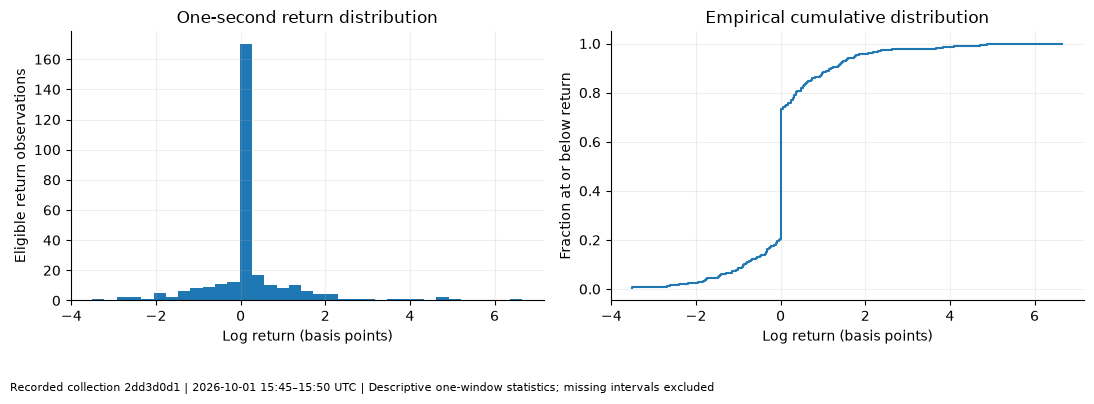

In [3]:
returns = one_second.log_return_bps.dropna()
display(returns.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(returns, bins=35)
axes[0].set(
    title="One-second return distribution",
    xlabel="Log return (basis points)",
    ylabel="Eligible return observations",
)
ordered = np.sort(returns.to_numpy())
axes[1].step(ordered, np.arange(1, len(ordered) + 1) / len(ordered))
axes[1].set(
    title="Empirical cumulative distribution",
    xlabel="Log return (basis points)",
    ylabel="Fraction at or below return",
)
finish_plot(fig, sample, "Descriptive one-window statistics; missing intervals excluded")

## 3. Sampling changes the question

One-second returns ask about rapid movement; thirty-second returns ask about a
longer interval. Compare their magnitudes alongside their sample counts. At a
thirty-second horizon this one market supplies very few observations.

,horizon_s,return_count,mean_bps,std_bps,largest_absolute_bps
0,1,298,0.146975,1.085559,6.659636
1,5,58,0.730837,2.877057,7.429713
2,30,8,5.124192,6.645297,14.635358


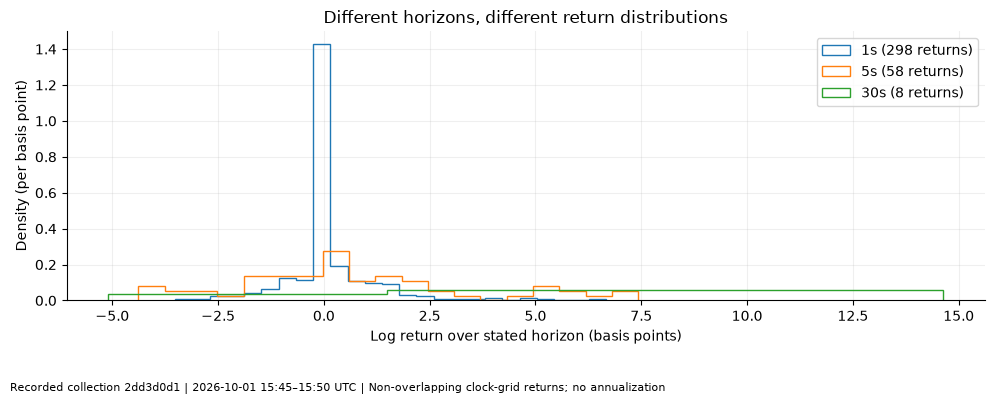

In [4]:
horizon_results = []
fig, ax = plt.subplots()
for horizon in [1, 5, 30]:
    values = btc_grid(sample, seconds=horizon).log_return_bps.dropna()
    horizon_results.append(
        {
            "horizon_s": horizon,
            "return_count": len(values),
            "mean_bps": values.mean(),
            "std_bps": values.std(),
            "largest_absolute_bps": values.abs().max(),
        }
    )
    if len(values):
        ax.hist(
            values,
            bins=min(25, max(3, len(values) // 3)),
            density=True,
            histtype="step",
            label=f"{horizon}s ({len(values)} returns)",
        )
display(pd.DataFrame(horizon_results))
ax.set(
    title="Different horizons, different return distributions",
    xlabel="Log return over stated horizon (basis points)",
    ylabel="Density (per basis point)",
)
ax.legend()
finish_plot(fig, sample, "Non-overlapping clock-grid returns; no annualization")

## 4. Volatility is variation, not a direction signal

The next estimate is the standard deviation of the last twenty one-second returns.
It requires all twenty points, so gaps reset it. This is a descriptive local
estimate, not a calibrated forecast of the next five minutes.

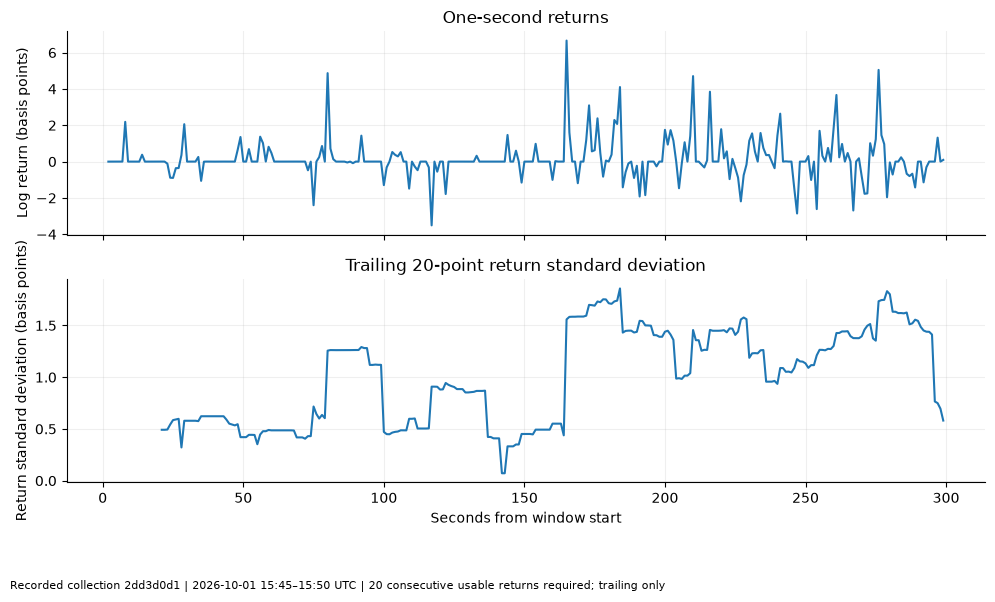

In [5]:
series = one_second.set_index("time").log_return_bps
rolling = series.rolling(20, min_periods=20).std()
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(seconds, one_second.log_return_bps)
axes[0].set(title="One-second returns", ylabel="Log return (basis points)")
axes[1].plot(seconds, rolling.to_numpy())
axes[1].set(
    title="Trailing 20-point return standard deviation",
    xlabel="Seconds from window start",
    ylabel="Return standard deviation (basis points)",
)
finish_plot(fig, sample, "20 consecutive usable returns required; trailing only")

## 5. Autocorrelation without silently closing gaps

We correlate the regular-time series with shifted versions, retaining missing
points in their original positions. Dropping missing timestamps before shifting
would create a new, misleading clock. Correlation here is exploratory and may
reflect microstructure, chance, or a short-lived pattern.

1     0.235108
2     0.093805
3     0.001250
4    -0.061356
5    -0.125315
6    -0.044899
7    -0.003206
8     0.098421
9    -0.071601
10    0.038586
Name: Correlation, dtype: float64

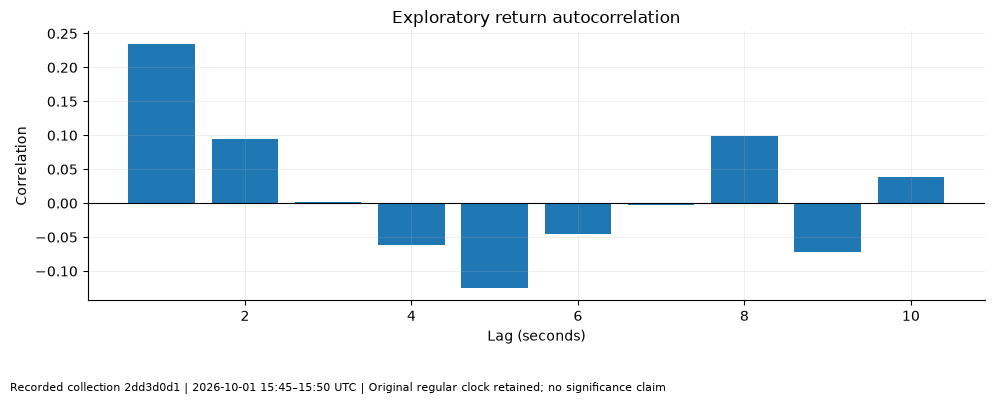

In [6]:
acf = pd.Series({lag: series.corr(series.shift(lag)) for lag in range(1, 11)}, name="Correlation")
display(acf)
fig, ax = plt.subplots()
ax.bar(acf.index, acf.values)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Exploratory return autocorrelation", xlabel="Lag (seconds)", ylabel="Correlation")
finish_plot(fig, sample, "Original regular clock retained; no significance claim")

## Exercise — change the horizon and explain the trade-off

Change the horizons to 2, 10 and 60 seconds. Which horizon looks more volatile,
and how many observations support that impression?

**Suggested answer:** a longer horizon often has larger raw return magnitudes,
but supplies fewer observations. Comparing raw standard deviations alone is not
a volatility-forecast contest. One window cannot establish Gaussian returns,
stable autocorrelation or a predictable regime.

**Research use:** trailing volatility and activity may become causal features.
**What remains unknown:** their out-of-sample predictive value, representative
regime coverage, and the part of measured movement due to trade-price bounce.

Next: [05 — Order-book liquidity](05_order_book_and_liquidity.ipynb).